# Module: Population dust attenuation model (per-particle)

> A calibrated two-component dust attenuation model -- ported from the
> SPHEREx `Mocks_v3` production pipeline
> (`/lcrc/project/cosmo_ai/nramachandra/Projects/SPHEREx/Mocks_v3/pipeline/dust_model.py`)
> -- adapted to attenuate the per-star-particle SEDs `watercolor` builds
> directly from HACC catalogs, instead of the tabular-SFH + FSPS route
> `Mocks_v3` uses for its supermock.

## Why this replaces `watercolor.dust_attenuation.spectrum_dusted`

The existing `spectrum_dusted` (in `dust_attenuation.py`, `duste`-based) has
the same failure modes documented in `04b_dust_attenuation_calibrated.ipynb`:
DustE's valid parameter ranges (`z in [0.51, 2.83]`, `logM in [8.74, 11.30]`,
...) don't cover most HACC galaxies, and it silently extrapolates into
unphysical attenuation. `04b` already ported the *physics* (Noll+09 modified
Calzetti + Charlot & Fall birth cloud) and verified it against `sedpy`. This
notebook goes one step further and makes it the thing `Mocks_v3`'s supermock
actually uses in production:

* the **same parametrisation** (`a, b, c, d, e, sigma, n, mu`) and JSON
  contract. A population dust calibration is tied to the dust-free SEDs it
  was fit on, so the default parameters here are calibrated on
  `watercolor`'s *own* particle-built SEDs against SDSS
  (`08_observational_comparison.ipynb` ->
  `watercolor/data/dust_model/dust_model_watercolor.json`). The `Mocks_v3`
  / `SEDPhot_v2` fit is still bundled (`DUST_MODEL_JSON_MOCKS_V3`) for
  comparison;
* a **new** ingredient `Mocks_v3` doesn't need: `watercolor` builds SEDs
  particle-by-particle (`calc_fluxes_for_individual_galaxy`), so there is no
  tabular SFH to read log sSFR off of. This notebook adds
  `recent_sfr_from_particles`, an SFR estimator from the star-particle age
  distribution (mass formed within a lookback window, default 100 Myr), so
  the model's sSFR term (`e`) is usable here too;
* two things only a per-particle pipeline can do: a Charlot & Fall
  **birth-cloud screen on exactly the light of <10 Myr stars** (`tau_bc`),
  and **energy-balance dust emission** (`add_dust_emission`, DL07
  templates) so the mid-IR is there for WISE / SPHEREx.

## Scope

This notebook covers item (1) of a 3-part plan: get `watercolor`'s dust
model on par with the calibrated supermock. It validates the port (curve
equivalence, before/after vs. the old DustE model, spectral shape/color/
luminosity sanity checks against example supermock SEDs). Two things are
**explicitly out of scope here**:

* **(2) observational comparison report** (SDSS/DEEP2/WISE color loci, GAMA
  SED stacks, etc., like `Mocks_v3_data/reports/patch0`) -- a separate
  follow-up notebook;
* **(3) performance** -- per-particle SED synthesis is much more expensive
  than FSPS-on-tabular-SFH; a job for later.

`watercolor.paint` uses this model by default (`dust='population'`); the
old DustE route is still available there as `dust='duste'`.

In [ ]:
#| default_exp dust_model

In [ ]:
#| hide
from nbdev.showdoc import *

In [ ]:
#| hide

# Imports used only by this notebook's demo/validation cells below (never
# part of the exported watercolor.dust_model module). Kept in one pure-
# import cell, separate from the cells that use them: nbdev's docs-build
# pass (exec_show_docs) only re-executes cells that are #|export, contain
# show_doc(...), or themselves contain an import -- a later cell that is
# neither of those (e.g. a plain "dust_model = load_default_dust_model()")
# is silently skipped in that pass. Mixing an import into a cell that also
# depends on such a skipped cell's state breaks the docs build with a
# NameError; keeping demo cells import-free avoids that entirely.
import matplotlib.pyplot as plt
from sedpy.attenuation import calzetti, noll
from astropy.cosmology import FlatLambdaCDM

/home/nramachandra/anaconda3/envs/opencosmo_env/lib/python3.12/site-packages/sedpy/observate.py:12: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename, resource_listdir


## Attenuation curves

Exact mirrors of `sedpy.attenuation.calzetti` / `noll` (what DustE uses
internally) -- so the underlying physics is unchanged from DustE, only the
*parameter assignment* differs. Canonical maintained copy:
`SPHEREx/Mocks_v3/pipeline/dust_model.py`.

In [ ]:
#| export
import os
import json
import numpy as np
from functools import lru_cache
from importlib.resources import files as _pkg_files

from watercolor.dust_attenuation import log_total_stellar_mass, log_total_stellar_metal

In [ ]:
#| export

R_V_CALZETTI = 4.05 # Calzetti (2000) R_V


def calzetti_k_over_kv(wave_aa:np.ndarray=None, # REST-FRAME wavelength (Angstrom)
                       )-> np.ndarray: # Calzetti (2000) curve, normalized to 1 at 5500 A
    """Exact mirror of `sedpy.attenuation.calzetti(wave, tau_v=1, R_v=4.05)`:
    published polynomials on 1200-6300 A (UV) and 6300-22000 A (optical/NIR),
    linear extrapolation outside, clipped at zero."""
    wave = np.asarray(wave_aa, dtype=float)
    r_v = R_V_CALZETTI

    def k_opt(x):    # optical/NIR polynomial, x = 1e4/lambda[A] = 1/lambda[um]
        return 2.659 * (-1.857 + 1.040 * x)

    def k_uv(x):     # UV polynomial
        return 2.659 * (-2.156 + 1.509 * x - 0.198 * x ** 2 + 0.011 * x ** 3)

    uv_anchor = np.array([1200.0, 1300.0])
    kuv_anchor = k_uv(1e4 / uv_anchor) + r_v
    uv_slope = np.diff(kuv_anchor)[0] / np.diff(uv_anchor)[0]
    ir_anchor = np.array([21900.0, 22000.0])
    kir_anchor = k_opt(1e4 / ir_anchor) + r_v
    ir_slope = np.diff(kir_anchor)[0] / np.diff(ir_anchor)[0]
    k_v = k_uv(1e4 / 5500.0) + r_v

    x = 1e4 / wave
    ktot = np.where(wave < 1200.0,
                    kuv_anchor[0] + (wave - uv_anchor[0]) * uv_slope, 0.0)
    ktot = np.where((wave >= 1200.0) & (wave < 6300.0), k_uv(x) + r_v, ktot)
    ktot = np.where((wave >= 6300.0) & (wave <= 22000.0), k_opt(x) + r_v, ktot)
    ktot = np.where(wave > 22000.0,
                    kir_anchor[1] + (wave - ir_anchor[1]) * ir_slope, ktot)
    ktot = np.clip(ktot, 0.0, None)
    return ktot / k_v


def drude_bump(wave_aa:np.ndarray=None, # REST-FRAME wavelength (Angstrom)
              x0:np.float32=4.59, # Bump center (inverse micron)
              gamma:np.float32=0.90, # Bump width (inverse micron)
              )-> np.ndarray: # Drude profile, peak normalized to 1
    """2175 A UV bump -- identical to `sedpy.attenuation.drude`."""
    x = 1e4 / np.asarray(wave_aa, dtype=float)
    return (x * gamma) ** 2 / ((x ** 2 - x0 ** 2) ** 2 + (x * gamma) ** 2)


def tau_diffuse(wave_aa:np.ndarray=None, # REST-FRAME wavelength (Angstrom)
               tau_v:np.float32=None, # Diffuse V-band optical depth
               n:np.float32=0.0, # Noll+09 slope modifier (0 = Calzetti)
               apply_bump:bool=True, # Tie a 2175 A bump amplitude to `n`
               )-> np.ndarray: # Diffuse-ISM optical depth vs wavelength
    """Noll+09 modified-Calzetti diffuse-ISM screen. Exact mirror of
    `sedpy.attenuation.noll(wave, tau_v, delta=n, c_r=0, Ebump=0.85-1.9n)`,
    which is DustE's `get_dust_attn_curve_d2`. `n=0, apply_bump=False` is
    pure Calzetti with `tau(5500)=tau_v`."""
    wave_aa = np.asarray(wave_aa, dtype=float)
    k = calzetti_k_over_kv(wave_aa)
    if apply_bump:
        ebump = 0.85 - 1.9 * n
        k = k + (ebump / R_V_CALZETTI) * drude_bump(wave_aa)
    tau = tau_v * k * (wave_aa / 5500.0) ** n
    return np.clip(tau, 0.0, None)


def tau_birthcloud(wave_aa:np.ndarray=None, # REST-FRAME wavelength (Angstrom)
                   tau1:np.float32=None, # Birth-cloud optical depth at 5500 A
                   )-> np.ndarray: # Birth-cloud optical depth vs wavelength
    """Charlot & Fall (2000) birth-cloud screen, slope -1 (DustE's `dust1`)."""
    return tau1 * (np.asarray(wave_aa, dtype=float) / 5500.0) ** (-1.0)


def attenuate(spec:np.ndarray=None, # SED, any flux/luminosity density units, shape (..., nwave)
             wave_rest_aa:np.ndarray=None, # REST-FRAME wavelength (Angstrom), shape (nwave,)
             tau_v:np.float32=None, # Diffuse V-band optical depth, scalar or broadcastable to spec[...,None]
             n:np.float32=0.0, # Noll+09 slope modifier
             mu:np.float32=0.0, # Birth-cloud amplitude, tau_BC(V) = mu * tau_v
             apply_bump:bool=True, # Tie a 2175 A bump amplitude to `n`
             )-> np.ndarray: # Attenuated SED, same shape/units as `spec`
    """Apply the two-component screen to a rest-frame spectrum. `wave_rest_aa`
    MUST be rest-frame -- feeding observed-frame wavelengths silently shifts
    the curve by `(1+z)`, the exact DustE failure mode this replaces."""
    tau_v = np.asarray(tau_v, dtype=float)
    if tau_v.ndim > 0:
        tau_v = tau_v[..., None]
    tau = tau_diffuse(wave_rest_aa, 1.0, n=n, apply_bump=apply_bump) * tau_v
    if np.any(np.asarray(mu) > 0):
        tau = tau + tau_birthcloud(wave_rest_aa, 1.0) * (mu * tau_v)
    return spec * np.exp(-tau)

### Verification against `sedpy`

Same check as `04b`: the curves above must be bit-for-bit consistent with
`sedpy.attenuation` (the reference DustE itself calls into).

In [ ]:
wave_test = np.linspace(300.0, 40000.0, 4000)
err_calz = np.max(np.abs(calzetti_k_over_kv(wave_test)
                         - calzetti(wave_test, tau_v=1.0, R_v=4.05)))
errs_noll = []
for tv in (0.1, 0.5, 1.5):
    for n in (-0.5, -0.1, 0.0, 0.3):
        ref = np.clip(noll(wave_test, tau_v=tv, delta=n, c_r=0.0,
                           Ebump=0.85 - 1.9 * n), 0.0, None)
        errs_noll.append(np.max(np.abs(tau_diffuse(wave_test, tv, n) - ref)))

print(f"max |ours - sedpy.calzetti| = {err_calz:.2e}")
print(f"max |ours - sedpy.noll|     = {max(errs_noll):.2e}")
assert err_calz < 1e-10 and max(errs_noll) < 1e-10
print("curves are identical to the sedpy/DustE forms")

max |ours - sedpy.calzetti| = 0.00e+00
max |ours - sedpy.noll|     = 3.55e-15
curves are identical to the sedpy/DustE forms


## Population `tau_V` model + calibrated parameters

Each galaxy draws its own diffuse V-band optical depth from its properties:

$$\tau_V = a\,10^{b(\log M_*-10)}\,10^{c\,\log Z}\,(1+z)^d\,
10^{e(\log\mathrm{sSFR}+10)}\,e^{\sigma\mathcal{N}(0,1)},
\qquad \tau_V \in [\tau_{min}, \tau_{max}]$$

identical to `Mocks_v3/pipeline/dust_model.DustModel` (kept import-compatible
with its JSON `save`/`load` so a recalibration there can be dropped in
here directly).

In [ ]:
#| export

class DustModel:
    """Population dust model with calibratable parameters.

    tau_V,mean = a * 10^{b(logM-10)} * 10^{c logZ} * (1+z)^d
                   * 10^{e (log sSFR + 10)}
    tau_V,i = tau_V,mean * exp(sigma * N_i(0,1)),  clipped to [tau_min, tau_max]

    Attenuation curve: Noll+09 (slope n, bump tied) + mu * Charlot-Fall.
    `tau_bc` (watercolor extension, default 0 = off): extra Charlot & Fall
    birth-cloud optical depth (at 5500 A, slope -1) seen ONLY by stars younger
    than ~10 Myr. A per-particle pipeline knows which light that is
    (`calc_csp_for_galaxies` returns it), so it does not have to be smeared
    over the whole spectrum the way `mu` is.
    Identical contract to `SPHEREx/Mocks_v3/pipeline/dust_model.DustModel` --
    a JSON calibrated there (`DustModel.save`) loads here unchanged.
    """

    #: default (uncalibrated) parameters -- Calzetti-like, Garn & Best (2010)
    #: inspired mass scaling; superseded by `load_default_dust_model()`.
    DEFAULTS = dict(a=0.30, b=0.50, c=0.30, d=0.30, e=0.0,
                    sigma=0.35, n=-0.10, mu=0.0, tau_bc=0.0,
                    tau_min=0.005, tau_max=4.0, apply_bump=True)

    PARAM_NAMES = ('a', 'b', 'c', 'd', 'e', 'sigma', 'n', 'mu', 'tau_bc')

    def __init__(self, **kwargs):
        params = dict(self.DEFAULTS)
        unknown = set(kwargs) - set(params)
        if unknown:
            raise ValueError(f"Unknown DustModel parameters: {sorted(unknown)}")
        params.update(kwargs)
        for key, val in params.items():
            setattr(self, key, val)
        self.meta = {}

    # ---------------------------------------------------------------- tau_V
    def tau_v_mean(self, logmass, logz=0.0, redshift=0.0, log_ssfr=None):
        """Mean diffuse V-band optical depth for given galaxy properties.

        logmass : log10(M*/Msun);  logz : log10(Z/Zsun);  redshift : z
        log_ssfr: log10(SFR/M*) [1/yr]; enters as 10^{e (log_ssfr + 10)}
                  (pivot sSFR = 1e-10/yr), clipped to [-13, -8]. If None,
                  the sSFR term is skipped (only valid when e == 0).
        """
        logmass = np.asarray(logmass, dtype=float)
        logz = np.asarray(logz, dtype=float)
        redshift = np.asarray(redshift, dtype=float)
        tau = (self.a
               * 10.0 ** (self.b * (logmass - 10.0))
               * 10.0 ** (self.c * np.clip(logz, -2.0, 0.5))
               * (1.0 + np.clip(redshift, 0.0, 6.0)) ** self.d)
        if self.e != 0.0:
            if log_ssfr is None:
                raise ValueError('DustModel has e != 0: pass log_ssfr '
                                 '(= log_sfr - logmass).')
            lss = np.clip(np.asarray(log_ssfr, dtype=float), -13.0, -8.0)
            tau = tau * 10.0 ** (self.e * (lss + 10.0))
        return np.clip(tau, self.tau_min, self.tau_max)

    def draw_tau_v(self, logmass, logz=0.0, redshift=0.0, rng=None,
                   log_ssfr=None):
        """tau_V with log-normal galaxy-to-galaxy scatter. With sigma == 0
        this is deterministic and no rng is consumed."""
        mean = self.tau_v_mean(logmass, logz, redshift, log_ssfr=log_ssfr)
        if self.sigma == 0.0:
            return mean
        if rng is None:
            rng = np.random.default_rng()
        scat = np.exp(self.sigma * rng.standard_normal(np.shape(mean)))
        return np.clip(mean * scat, self.tau_min, self.tau_max)

    # ----------------------------------------------------------- attenuation
    def attenuate(self, spec, wave_rest_aa, logmass, logz=0.0, redshift=0.0,
                  rng=None, tau_v=None, log_ssfr=None, spec_young=None):
        """Attenuate a rest-frame spectrum. Pass `tau_v` explicitly to bypass
        the population draw (reproducibility). `spec_young` is the part of
        `spec` emitted by stars still in their birth clouds; it is dimmed by
        the extra `tau_bc` screen before the diffuse dust acts on everything."""
        if tau_v is None:
            tau_v = self.draw_tau_v(logmass, logz, redshift, rng=rng,
                                    log_ssfr=log_ssfr)
        if spec_young is not None and self.tau_bc > 0:
            spec = spec - spec_young * (1.0 - np.exp(-tau_birthcloud(wave_rest_aa, self.tau_bc)))
        return attenuate(spec, wave_rest_aa, tau_v,
                         n=self.n, mu=self.mu, apply_bump=self.apply_bump), tau_v

    def transmission(self, wave_rest_aa, tau_v):
        """exp(-tau_total) for given tau_V (diagnostics/plots)."""
        one = np.ones_like(np.asarray(wave_rest_aa, dtype=float))
        return attenuate(one, wave_rest_aa, tau_v,
                         n=self.n, mu=self.mu, apply_bump=self.apply_bump)

    # ---------------------------------------------------------- (de)serialize
    def to_dict(self):
        d = {k: getattr(self, k) for k in self.DEFAULTS}
        d['meta'] = self.meta
        return d

    def save(self, path):
        with open(path, 'w') as f:
            json.dump(self.to_dict(), f, indent=2)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            d = json.load(f)
        meta = d.pop('meta', {})
        model = cls(**d)
        model.meta = meta
        return model

    def __repr__(self):
        pars = ', '.join(f'{k}={getattr(self, k):.4g}' for k in self.PARAM_NAMES)
        return f"DustModel({pars})"

### Bundled calibrations

Two parameter files ship with `watercolor` (same JSON contract as `04b` / `Mocks_v3`, plus the optional `tau_bc`):

* `dust_model_watercolor.json` (**default**, `DUST_MODEL_JSON`) -- fit in `08_observational_comparison.ipynb` to (z, i)-matched SDSS `u-g, g-r, r-i, i-z` distributions, on SEDs built the way this package builds them. `tau_V` there depends on stellar mass *and* sSFR (`e > 0`: the dust sits on the star-forming galaxies), with a birth-cloud term on the young stars.
* `dust_model_calibrated.json` (`DUST_MODEL_JSON_MOCKS_V3`) -- snapshot of the `SEDPhot_v2` fit used for the supermock, calibrated on FSPS tabular-SFH SEDs. On `watercolor`'s SEDs it is a *worse* match to SDSS than no dust at all (see `08`): it has no sSFR dependence, so it reddens the quenched red sequence as much as the star-forming galaxies.

Pass an explicit `path` to `load_default_dust_model` to use either, or a fresher recalibration.

In [ ]:
#| export

DUST_MODEL_DIR = "data/dust_model/"
# Calibrated on watercolor's own particle-built SEDs against SDSS (08_observational_comparison.ipynb)
DUST_MODEL_JSON = str(_pkg_files("watercolor").joinpath(DUST_MODEL_DIR, "dust_model_watercolor.json"))
# Snapshot of the Mocks_v3 / SEDPhot_v2 calibration (fit on FSPS tabular-SFH SEDs, not on watercolor's)
DUST_MODEL_JSON_MOCKS_V3 = str(_pkg_files("watercolor").joinpath(DUST_MODEL_DIR, "dust_model_calibrated.json"))


def load_default_dust_model(path:str=None, # Calibrated-parameter JSON; None -> bundled snapshot
                            )-> DustModel: # Calibrated population dust model
    return DustModel.load(path or DUST_MODEL_JSON)

In [ ]:
dust_model = load_default_dust_model()
print(dust_model)
print('calibrated to:', dust_model.meta.get('calibrated_to'))

DustModel(a=0.2647, b=0.4106, c=0, d=0, e=0.3453, sigma=0.1193, n=-0.2963, mu=0, tau_bc=0.6736)
calibrated to: ['SDSS']


<>:13: SyntaxWarning: invalid escape sequence '\p'
<>:35: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\p'
<>:35: SyntaxWarning: invalid escape sequence '\s'
/tmp/nramachandra/ipykernel_1411176/616447081.py:13: SyntaxWarning: invalid escape sequence '\p'
  ax.set_title('Calibrated mean relation ($\pm1\sigma$ scatter)')
/tmp/nramachandra/ipykernel_1411176/616447081.py:35: SyntaxWarning: invalid escape sequence '\s'
  f"($\sigma$={dust_model.sigma:.2f})")


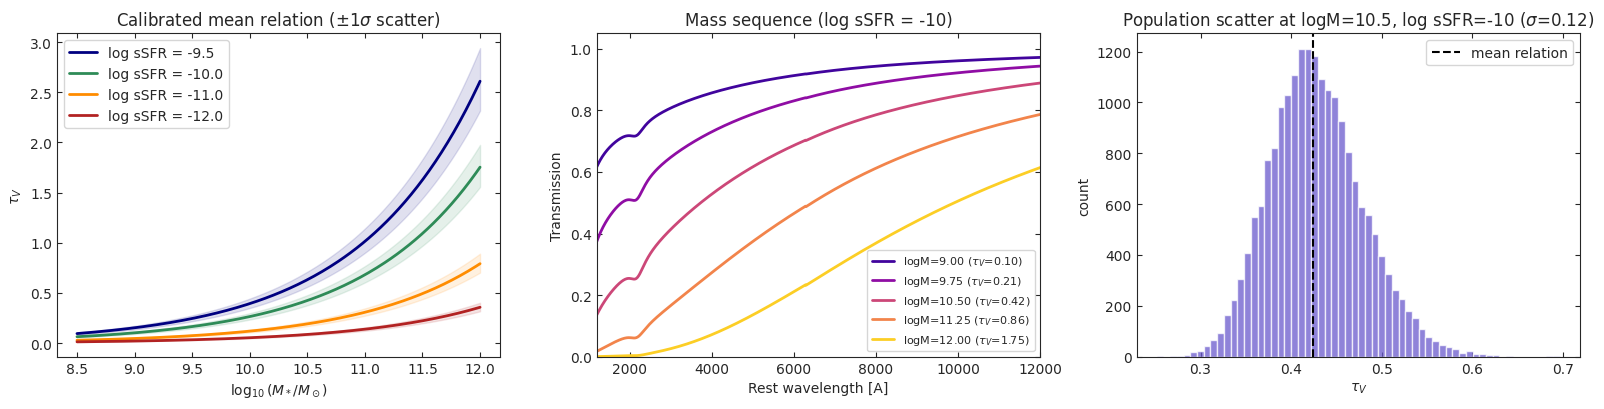

In [ ]:
wave = np.linspace(1200, 30000, 2000)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
logM = np.linspace(8.5, 12.0, 200)
LOG_SSFR_SF = -10.0  # a main-sequence galaxy; the default calibration has e > 0, so tau_V needs an sSFR
for log_ssfr, c in [(-9.5, 'navy'), (-10.0, 'seagreen'), (-11.0, 'darkorange'), (-12.0, 'firebrick')]:
    mean = dust_model.tau_v_mean(logM, 0.0, 0.0, log_ssfr=log_ssfr)
    ax.plot(logM, mean, color=c, lw=2, label=f'log sSFR = {log_ssfr}')
    ax.fill_between(logM, mean * np.exp(-dust_model.sigma),
                    mean * np.exp(dust_model.sigma), color=c, alpha=0.12)
ax.set_xlabel(r'$\log_{10}(M_*/M_\odot)$'); ax.set_ylabel(r'$\tau_V$')
ax.set_title('Calibrated mean relation ($\pm1\sigma$ scatter)')
ax.legend()

ax = axes[1]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, 5))
for logM_val, c in zip([9.0, 9.75, 10.5, 11.25, 12.0], colors):
    tv = float(dust_model.tau_v_mean(logM_val, 0.0, 0.0, log_ssfr=LOG_SSFR_SF))
    trans = dust_model.transmission(wave, tv)
    ax.plot(wave, trans, color=c, lw=2,
            label=f'logM={logM_val:.2f} ' + r'($\tau_V$=' + f'{tv:.2f})')
ax.set_xlim(1200, 12000); ax.set_ylim(0, 1.05)
ax.set_xlabel('Rest wavelength [A]'); ax.set_ylabel('Transmission')
ax.set_title('Mass sequence (log sSFR = -10)'); ax.legend(fontsize=8)

ax = axes[2]
rng = np.random.default_rng(42)
draws = dust_model.draw_tau_v(np.full(20000, 10.5), 0.0, 0.1, rng=rng, log_ssfr=LOG_SSFR_SF)
ax.hist(draws, bins=60, color='slateblue', alpha=0.75)
ax.axvline(float(dust_model.tau_v_mean(10.5, 0.0, 0.1, log_ssfr=LOG_SSFR_SF)), color='k', ls='--',
           label='mean relation')
ax.set_xlabel(r'$\tau_V$'); ax.set_ylabel('count')
ax.set_title(r'Population scatter at logM=10.5, log sSFR=-10 '
             f"($\sigma$={dust_model.sigma:.2f})")
ax.legend()
plt.tight_layout(); plt.show()

## Recent SFR from star particles

`Mocks_v3` reads log sSFR straight off the tabular SFH it feeds FSPS. `watercolor` has no tabular SFH -- it has a bag of star particles per galaxy, each with its own formation age. The substitute: the mass of the particles formed within a lookback window, divided by that window.

The window matters. One HACC star particle is ~3e8 Msun, so over 100 Myr a single particle *is* 3 Msun/yr -- more than the whole star-forming main sequence below `logM* ~ 10.5`. A 100 Myr estimate is therefore shot noise: 82% of z=0 galaxies have no such particle at all, although 50-75% of them are forming stars by their 1 Gyr average and by their star-forming gas (`08` has the numbers). `recent_sfr_from_particles` keeps 100 Myr as its own default, but `attenuate_particle_sed` uses **1 Gyr** for the sSFR that enters `tau_V` (the default calibration has `e = 0.35`).

In [ ]:
#| export

def recent_sfr_from_particles(age_gyr_i:np.ndarray=None, # Per-particle stellar age (Gyr)
                              mass_i:np.ndarray=None,     # Per-particle stellar mass (Msun)
                              window_gyr:np.float32=0.1,  # Lookback window (Gyr); default 100 Myr
                              sfr_floor:np.float32=1e-4,  # Floor (Msun/yr), keeps log10 finite for quenched galaxies
                              )-> np.array: # Recent SFR (Msun/yr), floored at `sfr_floor`
    age_gyr_i = np.asarray(age_gyr_i, dtype=float)
    mass_i = np.asarray(mass_i, dtype=float)
    formed_recent = mass_i[age_gyr_i <= window_gyr].sum()
    sfr = formed_recent / (window_gyr * 1e9)
    return np.array([max(sfr, sfr_floor)])


def log_sfr_from_particles(age_gyr_i:np.ndarray=None, # Per-particle stellar age (Gyr)
                           mass_i:np.ndarray=None,     # Per-particle stellar mass (Msun)
                           window_gyr:np.float32=0.1,  # Lookback window (Gyr)
                           sfr_floor:np.float32=1e-4,  # Floor (Msun/yr)
                           )-> np.float32: # log10(recent SFR / [Msun/yr])
    sfr = recent_sfr_from_particles(age_gyr_i, mass_i, window_gyr, sfr_floor)
    return float(np.log10(sfr)[0])

## Dust emission (energy balance)

Attenuation only *removes* light. The energy the dust absorbs comes back out in the infrared, and without it the painted SEDs have no PAH/warm-dust emission at all: WISE `W2-W3` comes out at about -0.9 (bare stellar Rayleigh-Jeans tail) where real galaxies sit at +2.6 to +3.6.

Same scheme as `Mocks_v3/pipeline/paint_seds.py`: the absorbed luminosity $L_{abs}=\int (L_\lambda^{\rm no\,dust}-L_\lambda^{\rm dusted})\,d\lambda$ is re-emitted with a Draine & Li (2007) spectral shape, $L_\lambda \mathrel{+}= L_{abs}\,T(\lambda;\log Z,\log{\rm sSFR})$, with $\int T\,d\lambda=1$. The templates were extracted from FSPS by `Mocks_v3/pipeline/make_dl07_templates.py` on a 6 x 11 grid in (log Z/Zsun, log sSFR); they are bundled here (`watercolor/data/dust_model/dl07_templates.npz`) resampled onto the SSP library's 1963-point wavelength grid and renormalised.

In [ ]:
#| export

DUST_EMISSION_TEMPLATES = str(_pkg_files("watercolor").joinpath(DUST_MODEL_DIR, "dl07_templates.npz"))


@lru_cache(maxsize=2)
def load_dust_emission_templates(path:str=None, # Template file; None -> bundled DL07 set
                                 )-> dict: # wave_rest (A), templates [n_logz, n_lssfr, n_wave] (1/A), logz_grid, lssfr_grid
    with np.load(path or DUST_EMISSION_TEMPLATES) as f:
        return {k: f[k].astype(float) for k in ('wave_rest', 'templates', 'logz_grid', 'lssfr_grid')}


def dust_emission_template(logz:np.float32=0.0,        # log10(Z/Zsun) of the galaxy
                           log_ssfr:np.float32=-10.0,  # log10(sSFR [1/yr])
                           templates:dict=None,        # From load_dust_emission_templates; None -> bundled
                           )-> tuple: # (rest wavelength [A], emission per unit absorbed luminosity [1/A])
    """Bilinear interpolation of the DL07 template grid, clipped to its edges."""
    t = templates or load_dust_emission_templates()
    gz, gs, T = t['logz_grid'], t['lssfr_grid'], t['templates']
    iz = int(np.clip(np.searchsorted(gz, logz) - 1, 0, gz.size - 2))
    js = int(np.clip(np.searchsorted(gs, log_ssfr) - 1, 0, gs.size - 2))
    fz = np.clip((logz - gz[iz])/(gz[iz + 1] - gz[iz]), 0, 1)
    fs = np.clip((log_ssfr - gs[js])/(gs[js + 1] - gs[js]), 0, 1)
    template = ((1 - fz)*(1 - fs)*T[iz, js] + fz*(1 - fs)*T[iz + 1, js]
                + (1 - fz)*fs*T[iz, js + 1] + fz*fs*T[iz + 1, js + 1])
    return t['wave_rest'], template


def add_dust_emission(spec_rest:np.ndarray=None,     # Rest-frame SED before dust (Lsun/A)
                      spec_dusted:np.ndarray=None,   # The same SED after attenuation (Lsun/A)
                      wave_rest_aa:np.ndarray=None,  # Rest-frame wavelength grid (A)
                      logz:np.float32=0.0,           # log10(Z/Zsun) of the galaxy
                      log_ssfr:np.float32=-10.0,     # log10(sSFR [1/yr])
                      templates:dict=None,           # From load_dust_emission_templates; None -> bundled
                      )-> tuple: # (attenuated + re-emitted SED [Lsun/A], absorbed luminosity [Lsun])
    """Energy balance: whatever the attenuation removed is re-emitted in the IR."""
    l_abs = np.trapezoid(spec_rest - spec_dusted, wave_rest_aa)
    if not l_abs > 0:
        return spec_dusted, 0.0
    wave_t, template = dust_emission_template(logz, log_ssfr, templates)
    if wave_t.shape != np.shape(wave_rest_aa) or not np.allclose(wave_t, wave_rest_aa):
        template = np.interp(wave_rest_aa, wave_t, template, left=0.0, right=0.0)
    return spec_dusted + l_abs*template, float(l_abs)

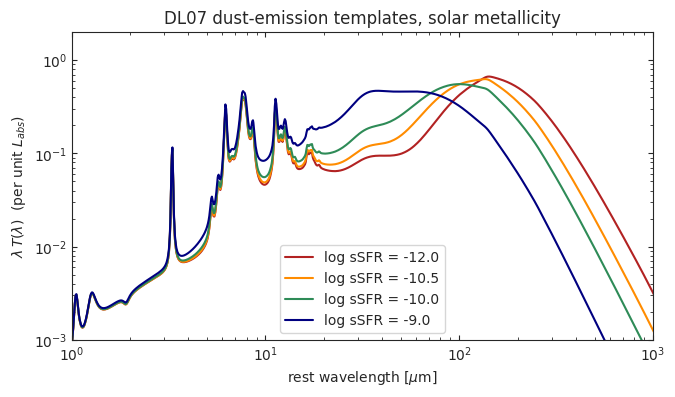

In [ ]:
_t = load_dust_emission_templates()
assert np.allclose(np.trapezoid(_t['templates'], _t['wave_rest'], axis=-1), 1.0, atol=1e-4)

fig, ax = plt.subplots(figsize=(7.5, 4))
for ls, c in [(-12.0, 'firebrick'), (-10.5, 'darkorange'), (-10.0, 'seagreen'), (-9.0, 'navy')]:
    w_t, tmpl = dust_emission_template(0.0, ls)
    ax.loglog(w_t/1e4, w_t*tmpl, color=c, label=f'log sSFR = {ls}')
ax.set_xlim(1, 1000); ax.set_ylim(1e-3, 2)
ax.set_xlabel(r'rest wavelength [$\mu$m]'); ax.set_ylabel(r'$\lambda\,T(\lambda)$  (per unit $L_{abs}$)')
ax.set_title('DL07 dust-emission templates, solar metallicity'); ax.legend(); plt.show()

## `attenuate_particle_sed`: drop-in per-particle dust attenuation

Same call pattern as `watercolor.dust_attenuation.spectrum_dusted` (SED,
rest-frame wave, per-particle properties, redshift) but analytic, calibrated
to SDSS+DEEP2+WISE, valid at any z and mass (no DustE extrapolation
failure), and includes the sSFR channel. `wave_rest_aa` must be REST-FRAME
Angstrom, same requirement as before.

In [ ]:
#| export

def attenuate_particle_sed(spec_rest:np.ndarray=None,     # Rest-frame SED (Lsun/A), no dust
                           wave_rest_aa:np.ndarray=None,   # Rest-frame wavelength grid (A)
                           mass_i:np.ndarray=None,         # Per-particle stellar mass (Msun)
                           metal_i:np.ndarray=None,        # Per-particle metallicity (Z/Zsun)
                           age_gyr_i:np.ndarray=None,      # Per-particle age (Gyr)
                           galaxy_redshift:np.float32=0.0, # Redshift
                           dust_model:DustModel=None,      # Population dust model; None -> load_default_dust_model()
                           rng:np.random.Generator=None,   # RNG for the tau_V draw; None -> fresh, non-reproducible
                           sfr_window_gyr:np.float32=1.0,  # Lookback window for the SFR estimate. 1 Gyr: with ~3e8 Msun particles a 100 Myr window is pure shot noise below logM*~10.5
                           spec_young:np.ndarray=None,     # Part of `spec_rest` from stars younger than ~10 Myr (birth-cloud dust); None -> no birth-cloud term
                           tau_v:np.float32=None,          # Pass to bypass the tau_V draw entirely
                           add_emission:bool=True,         # Re-emit the absorbed energy in the IR (DL07 templates)
                           )-> tuple: # (attenuated SED [Lsun/A], diagnostics dict)
    if dust_model is None:
        dust_model = load_default_dust_model()

    logmass = float(log_total_stellar_mass(mass_i)[0])
    logz = float(log_total_stellar_metal(metal_i, mass_i)[0])
    log_sfr = log_sfr_from_particles(age_gyr_i, mass_i, window_gyr=sfr_window_gyr)
    log_ssfr = log_sfr - logmass

    dusted, tau_v_used = dust_model.attenuate(spec_rest, wave_rest_aa, logmass, logz,
                                              galaxy_redshift, rng=rng, tau_v=tau_v,
                                              log_ssfr=log_ssfr, spec_young=spec_young)
    l_abs = 0.0
    if add_emission:
        dusted, l_abs = add_dust_emission(spec_rest, dusted, wave_rest_aa, logz, log_ssfr)
    diagnostics = dict(logmass=logmass, logz=logz, log_sfr=log_sfr,
                       log_ssfr=log_ssfr, tau_v=float(np.ravel(tau_v_used)[0]), l_abs=l_abs)
    return dusted, diagnostics

## `attenuate_particle_sed`: drop-in per-particle dust

Same call pattern as `watercolor.dust_attenuation.spectrum_dusted` (SED, rest-frame wave, per-particle properties, redshift) but analytic, calibrated, valid at any z and mass (no DustE extrapolation failure), and with the sSFR channel. `wave_rest_aa` must be REST-FRAME Angstrom, same requirement as before. Pass the young-star part of the CSP (`calc_fluxes_for_individual_galaxy(..., return_young_csp=True)`) as `spec_young` to get the birth-cloud term; the absorbed energy is re-emitted in the IR unless `add_emission=False`.

In [ ]:
import opencosmo as oc
from watercolor.load_sim_stellar_catalog import load_opencosmo_collection, Z_SOLAR_PADOVA, _opencosmo_age_to_gyr
from watercolor.calculate_csp import calc_fluxes_for_individual_galaxy
from watercolor.load_sps_library import (LIBRARY_FLUX_FILE, LIBRARY_WAVE_FILE,
                                         LIBRARY_AGE_FILE, LIBRARY_METAL_FILE)
from watercolor.dust_attenuation import spectrum_dusted

_STEP624 = ('/lcrc/project/cosmo_ai/nramachandra/Projects/Hydro_paint/Data/fromSciDAC/'
           '128MPC_RUNS_HACC_5PARAM/reformat/'
           'KAPPA_2.127_EGW_0.479_SEED_7.143e5_VKIN_3794_EPS_9.752/output/step_624/')
SCIDAC_GALPROP = _STEP624 + 'galaxyproperties/m000p-624.galaxyproperties.hdf5'
SCIDAC_GALPART = _STEP624 + 'galaxyparticles/m000p-624.galaxyparticles.hdf5'

collection = load_opencosmo_collection(particle_file_path=SCIDAC_GALPART, catalog_file_path=SCIDAC_GALPROP)
gal_props = collection['galaxy_properties'].get_data()
logms_all = np.log10(np.array(gal_props['gal_mass_star']))
gal_tags_all = np.array(gal_props['gal_tag'])

# three galaxies spanning the mass range the supermock examples cover below
targets = {}
for target_logm in (9.5, 10.5, 11.0):
    j = int(np.argmin(np.abs(logms_all - target_logm)))
    targets[target_logm] = int(gal_tags_all[j])
    print(f'target logM*={target_logm}: picked gal_tag={gal_tags_all[j]}, '
          f'logM*={logms_all[j]:.3f}')

sub = collection.filter(oc.col('gal_tag').isin(list(targets.values())))
star_data = sub['star_particles'].get_data()
gal_tag = np.array(star_data['gal_tag'])
mass = np.array(star_data['mass'])
mass_formed = np.array(star_data['initial_star_mass'])  # SSP weights: the library is per unit mass formed
metal = np.array(star_data['zmet']) / Z_SOLAR_PADOVA
age = _opencosmo_age_to_gyr(star_data['age'])

csp = {}
for target_logm, tag in targets.items():
    n_particles = int((gal_tag == tag).sum())
    spec_wave_ssp, spec_flux_ssp, spec_csp, flux_proxy, gal_stellar_mass, spec_csp_young = \
        calc_fluxes_for_individual_galaxy(gal_tag, metal, mass, age, tag,
            LIBRARY_FLUX_FILE, LIBRARY_WAVE_FILE, LIBRARY_AGE_FILE, LIBRARY_METAL_FILE,
            mass_formed_hacc=mass_formed, return_young_csp=True)
    csp[target_logm] = dict(wave=spec_wave_ssp, spec=spec_csp, spec_young=spec_csp_young, tag=tag,
                            mass_i=mass[gal_tag == tag], metal_i=metal[gal_tag == tag],
                            age_i=age[gal_tag == tag])
    print(f'logM*={target_logm}: n_particles={n_particles}, M*/L_bol={gal_stellar_mass/np.trapezoid(spec_csp, spec_wave_ssp):.2f} Msun/Lsun, '
          f'light from <10 Myr stars: {np.trapezoid(spec_csp_young, spec_wave_ssp)/np.trapezoid(spec_csp, spec_wave_ssp):.1%}')
print('CSPs (no dust) built for', list(csp.keys()))

target logM*=9.5: picked gal_tag=193737671, logM*=9.500
target logM*=10.5: picked gal_tag=19007773, logM*=10.500
target logM*=11.0: picked gal_tag=103539109, logM*=11.000


logM*=9.5: n_particles=13, M*/L_bol=0.04 Msun/Lsun, light from <10 Myr stars: 71.4%
logM*=10.5: n_particles=146, M*/L_bol=2.10 Msun/Lsun, light from <10 Myr stars: 0.0%


logM*=11.0: n_particles=482, M*/L_bol=2.18 Msun/Lsun, light from <10 Myr stars: 0.0%
CSPs (no dust) built for [9.5, 10.5, 11.0]


logM*=9.5: logM_actual=9.50 logZ=-0.08 log_sfr=-0.09 log_sSFR=-9.59 tau_V=0.229


logM*=10.5: logM_actual=10.50 logZ=0.05 log_sfr=-4.00 log_sSFR=-14.50 tau_V=0.039


logM*=11.0: logM_actual=11.00 logZ=0.13 log_sfr=-4.00 log_sSFR=-15.00 tau_V=0.063


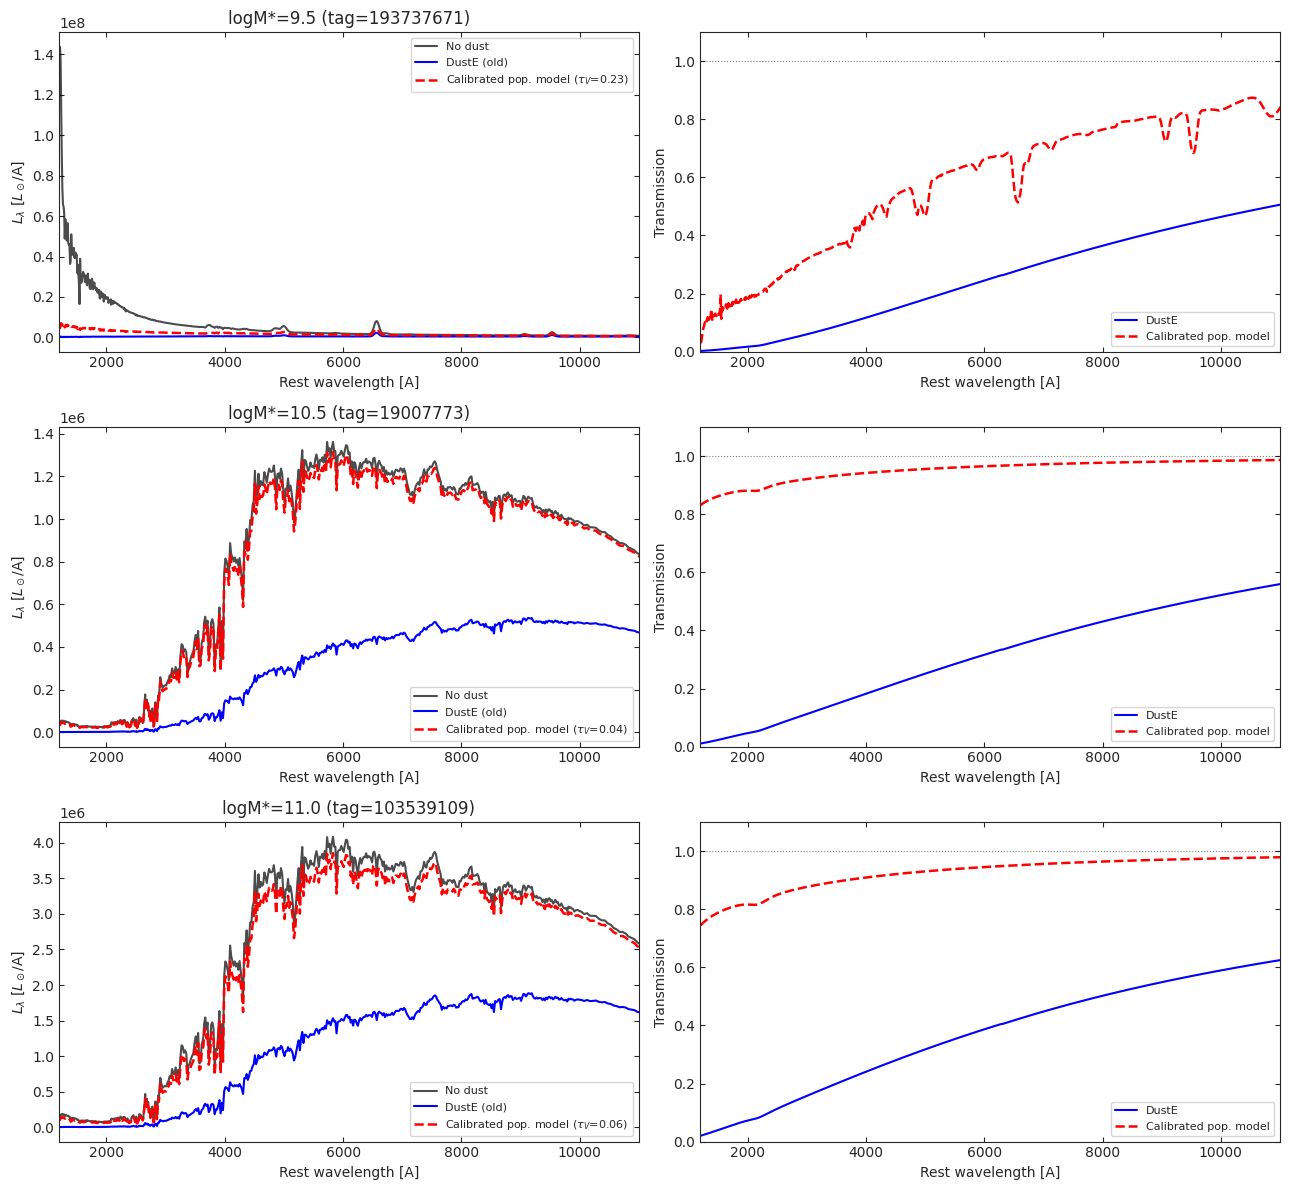

In [ ]:
from watercolor.dust_attenuation import log_total_stellar_mass, log_total_stellar_metal

GALAXY_Z = 0.1  # matches the supermock 'z=0.1' examples used below;
                # outside DustE's documented valid range z in [0.51, 2.83]
                # (see 04b) -- deliberately shows DustE extrapolating.

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for row, (target_logm, d) in enumerate(csp.items()):
    logmstar = log_total_stellar_mass(d['mass_i'])
    logZ = log_total_stellar_metal(d['metal_i'], d['mass_i'])

    spec_duste = spectrum_dusted(d['spec'], d['wave'], logmstar, logZ, GALAXY_Z)

    rng = np.random.default_rng(7)
    spec_new, diag = attenuate_particle_sed(d['spec'], d['wave'], d['mass_i'],
                                            d['metal_i'], d['age_i'], GALAXY_Z, rng=rng,
                                            spec_young=d['spec_young'])

    print(f"logM*={target_logm}: logM_actual={diag['logmass']:.2f} logZ={diag['logz']:.2f} "
          f"log_sfr={diag['log_sfr']:.2f} log_sSFR={diag['log_ssfr']:.2f} "
          f"tau_V={diag['tau_v']:.3f}")

    wmask = (d['wave'] >= 1200) & (d['wave'] <= 12000)
    wv = d['wave'][wmask]

    ax = axes[row, 0]
    ax.plot(wv, d['spec'][wmask], 'k-', lw=1.5, alpha=0.7, label='No dust')
    ax.plot(wv, spec_duste[wmask], 'b-', lw=1.5, label='DustE (old)')
    ax.plot(wv, spec_new[wmask], 'r--', lw=1.8,
            label=f"Calibrated pop. model ($\\tau_V$={diag['tau_v']:.2f})")
    ax.set_xlim(1200, 11000)
    ax.set_title(f"logM*={target_logm} (tag={int(d['tag'])})")
    ax.set_xlabel('Rest wavelength [A]'); ax.set_ylabel(r'$L_\lambda$ [$L_\odot$/A]')
    ax.legend(fontsize=8)

    ax = axes[row, 1]
    ax.plot(wv, spec_duste[wmask] / d['spec'][wmask], 'b-', lw=1.5, label='DustE')
    ax.plot(wv, spec_new[wmask] / d['spec'][wmask], 'r--', lw=1.8, label='Calibrated pop. model')
    ax.axhline(1.0, color='k', lw=0.8, ls=':', alpha=0.5)
    ax.set_xlim(1200, 11000); ax.set_ylim(0, 1.1)
    ax.set_xlabel('Rest wavelength [A]'); ax.set_ylabel('Transmission')
    ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

## Comparison against supermock example SEDs (`Mocks_v3`)

`Mocks_v3_data/reports/patch0/seds_examples.npz` ships 12 example supermock SEDs (FSPS on a tabular SFH + the `Mocks_v3` dust calibration), each tagged with its `(z, logM*)`. Three of them sit at `z~0.1`, spanning `logM* = 9.5, 10.5, 11.3` -- close to the three watercolor galaxies above.

These are different galaxies with different star-formation histories and (now) different dust calibrations, so this is a sanity check of spectral **shape**, not a test either side can fail: convert `L_lambda -> L_nu` (`x wave^2`), normalise both at rest 5500 A, and compare. The two quenched, well-sampled galaxies (`logM* = 10.5, 11.0`) have the same 4000 A break strength as their supermock counterparts to within 20-30%. The statistical comparison that actually constrains the model is in `08_observational_comparison.ipynb`.

watercolor logM*=9.5 <-> supermock example "z=0.1, logM*=9.5" (z=0.151)
watercolor logM*=10.5 <-> supermock example "z=0.1, logM*=10.5" (z=0.123)
watercolor logM*=11.0 <-> supermock example "z=0.1, logM*=11.3" (z=0.114)
logM*=9.5: blue(4000A)/red(7000A) ratio -- watercolor=0.67, supermock=0.17
logM*=10.5: blue(4000A)/red(7000A) ratio -- watercolor=0.17, supermock=0.14
logM*=11.0: blue(4000A)/red(7000A) ratio -- watercolor=0.16, supermock=0.22


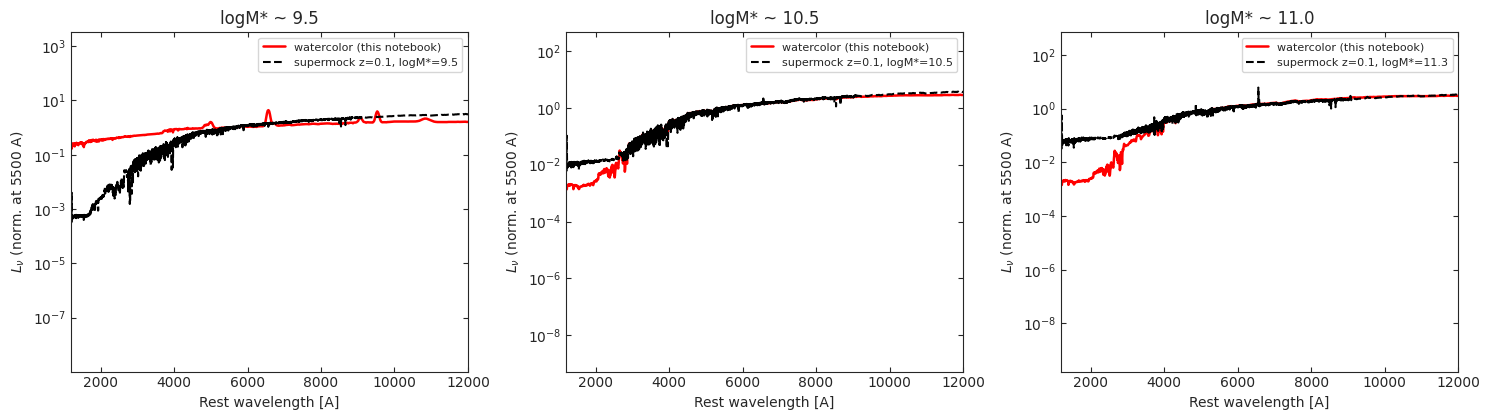

In [ ]:
SEDS_EXAMPLES = ('/lcrc/project/cosmo_ai/nramachandra/Projects/SPHEREx/'
                 'Mocks_v3_data/reports/patch0/seds_examples.npz')
C_AA_S = 2.99792458e18  # speed of light, A/s

sm = np.load(SEDS_EXAMPLES, allow_pickle=True)
sm_wave = sm['wave_rest']
sm_z = sm['z']; sm_logms = sm['logms']; sm_labels = sm['labels']

# the z~0.1 examples, matched to the three watercolor galaxies by logM*
z01 = np.where(np.char.startswith(sm_labels.astype(str), 'z=0.1'))[0]
match = {}
for target_logm in csp:
    j = z01[np.argmin(np.abs(sm_logms[z01] - target_logm))]
    match[target_logm] = j
    print(f'watercolor logM*={target_logm} <-> supermock example '
          f'"{sm_labels[j]}" (z={sm_z[j]:.3f})')

def pivot_normalize(wave, y, pivot_aa=5500.0):
    return y / np.interp(pivot_aa, wave, y)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (target_logm, d) in zip(axes, csp.items()):
    rng = np.random.default_rng(7)
    spec_new, diag = attenuate_particle_sed(d['spec'], d['wave'], d['mass_i'],
                                            d['metal_i'], d['age_i'], GALAXY_Z, rng=rng,
                                            spec_young=d['spec_young'])
    nu_shape_wc = pivot_normalize(d['wave'], spec_new * d['wave'] ** 2)

    j = match[target_logm]
    nu_shape_sm = pivot_normalize(sm_wave, sm['seds'][j])

    ax.plot(d['wave'], nu_shape_wc, 'r-', lw=1.8, label='watercolor (this notebook)')
    ax.plot(sm_wave, nu_shape_sm, 'k--', lw=1.5, label=f"supermock {sm_labels[j]}")
    ax.set_xlim(1200, 12000); ax.set_yscale('log')
    ax.set_xlabel('Rest wavelength [A]')
    ax.set_ylabel(r'$L_\nu$ (norm. at 5500 A)')
    ax.set_title(f'logM* ~ {target_logm}')
    ax.legend(fontsize=8)

    def band(w0, w1, wave, y):
        m = (wave >= w0) & (wave <= w1)
        return np.trapezoid(y[m], wave[m]) / (w1 - w0)
    blue_red_wc = band(3800, 4200, d['wave'], nu_shape_wc) / band(6800, 7200, d['wave'], nu_shape_wc)
    blue_red_sm = band(3800, 4200, sm_wave, nu_shape_sm) / band(6800, 7200, sm_wave, nu_shape_sm)
    print(f'logM*={target_logm}: blue(4000A)/red(7000A) ratio -- '
          f'watercolor={blue_red_wc:.2f}, supermock={blue_red_sm:.2f}')

plt.tight_layout(); plt.show()

### Bolometric luminosity

Watercolor's rest-frame CSP is `L_lambda` [Lsun/A], so `L_bol = integral(L_lambda, wave)` needs no distance/redshift bookkeeping, and with energy-balance re-emission it is the same before and after dust. The supermock SEDs are stored the other way around (observed-frame `f_nu` [Jy] at a given `z`), so getting `L_bol` from them needs the inverse of `Mocks_v3/pipeline/compute_luminosities.py`'s method: `L_bol = 4 pi d_L(z)^2 * sum(f_nu dnu_obs)`, with the cosmology the supermock was built with (`H0=67.77, Om0=0.307115`).

The two well-sampled galaxies come out at 0.6x (`logM*=10.5`) and 0.3x (`logM*=11.0` against a supermock example 0.3 dex *more* massive, i.e. ~0.55x per unit mass) of their supermock counterparts: both of ours are fully quenched (`M*/L_bol ~ 2.1`), the supermock examples are not. The `logM*=9.5` one is the opposite case and shows why single objects are not a test: it has only 13 star particles, a freshly formed one among them, so even after SFH smoothing 70% of its light comes from <10 Myr stars and its `L_bol` is 20x the (non-bursty) supermock example at the same mass. That is particle shot noise on one hand-picked object, which only a *statistical* comparison averages over -- see `08`.

In [ ]:
MOCKS_V3_COSMO = FlatLambdaCDM(H0=67.77, Om0=0.307115)
LSUN_ERG_S = 3.828e33
MPC_CM = 3.0856775814913673e24

def supermock_lbol_lsun(wave_rest_aa, fnu_jy, z):
    dl_cm = MOCKS_V3_COSMO.luminosity_distance(z).value * MPC_CM
    nu_rest = C_AA_S / wave_rest_aa
    dnu_rest = np.abs(np.gradient(nu_rest))
    dnu_obs = dnu_rest / (1.0 + z)
    return 4 * np.pi * dl_cm ** 2 * np.sum(fnu_jy * 1e-23 * dnu_obs) / LSUN_ERG_S

for target_logm, d in csp.items():
    rng = np.random.default_rng(7)
    spec_new, diag = attenuate_particle_sed(d['spec'], d['wave'], d['mass_i'],
                                            d['metal_i'], d['age_i'], GALAXY_Z, rng=rng,
                                            spec_young=d['spec_young'])
    l_bol_wc = np.trapezoid(spec_new, d['wave'])

    j = match[target_logm]
    l_bol_sm = supermock_lbol_lsun(sm_wave, sm['seds'][j], sm_z[j])
    n_particles = len(d['mass_i'])

    print(f"logM*={target_logm} ({n_particles} particles): L_bol watercolor={l_bol_wc:.3e} Lsun, "
          f"L_bol supermock ({sm_labels[j]})={l_bol_sm:.3e} Lsun, "
          f"ratio={l_bol_wc/l_bol_sm:.2f}")

logM*=9.5 (13 particles): L_bol watercolor=8.919e+10 Lsun, L_bol supermock (z=0.1, logM*=9.5)=4.421e+09 Lsun, ratio=20.17
logM*=10.5 (146 particles): L_bol watercolor=1.505e+10 Lsun, L_bol supermock (z=0.1, logM*=10.5)=2.426e+10 Lsun, ratio=0.62
logM*=11.0 (482 particles): L_bol watercolor=4.590e+10 Lsun, L_bol supermock (z=0.1, logM*=11.3)=1.645e+11 Lsun, ratio=0.28


## Smoke test on the production (2Gpc) OpenCosmo catalog

While building this notebook, `load_hacc_galaxy_data_opencosmo` turned out
to have a real, independent bug affecting the new single-file OpenCosmo
format: it returns `star_particles.age` **already assuming Gyr**, but
`with_units("physical")` actually tags that column as **yr** (verified
directly against this file's astropy `Column` unit) -- every age was
therefore ~1e9x too large, which collapses `calc_fluxes_for_individual_galaxy`'s
SSP age lookup to the oldest library bin for every star particle. That is
fixed upstream in `01_load_sim_stellar_catalog.ipynb`
(`_opencosmo_age_to_gyr`), independent of this dust model. This cell is a
smoke test of the fixed loader + this module on real production data; marked
`#|eval: false` since it depends on a large external path
(`Data/fromFE/haloparticles_2gpc.hdf5`, ~8GB) not guaranteed to exist
outside this cluster. Note also that this file's single-file OpenCosmo
format has no sub-halo `gal_tag`, so each "galaxy" below is really a whole
FOF halo (hence the cluster-scale `logM*`) -- not used for the supermock
comparison above for that reason.

In [ ]:
#|eval: false

from watercolor.load_sim_stellar_catalog import load_hacc_galaxy_data_opencosmo

PRODUCTION_CATALOG = ('/lcrc/project/cosmo_ai/nramachandra/Projects/Hydro_paint/'
                      'Data/fromFE/haloparticles_2gpc.hdf5')

out = load_hacc_galaxy_data_opencosmo(particle_file_path=PRODUCTION_CATALOG, num_halos=1)
fof_halo_tag, if_satellite, gal_tag, stellar_idx, metal_p, mass_p, age_p, x, y, z, vx, vy, vz = out
print(f'age range (Gyr): {age_p.min():.3f} - {age_p.max():.3f} '
      '(should be within [0, ~13.8], NOT ~1e9 larger)')

tag_p = np.unique(gal_tag)[0]
spec_wave_p, spec_flux_p, spec_csp_p, flux_proxy_p, gal_stellar_mass_p = \
    calc_fluxes_for_individual_galaxy(gal_tag, metal_p, mass_p, age_p, tag_p,
        LIBRARY_FLUX_FILE, LIBRARY_WAVE_FILE, LIBRARY_AGE_FILE, LIBRARY_METAL_FILE)

spec_new_p, diag_p = attenuate_particle_sed(spec_csp_p, spec_wave_p,
                                            mass_p[gal_tag == tag_p],
                                            metal_p[gal_tag == tag_p],
                                            age_p[gal_tag == tag_p], GALAXY_Z)
print(f'FOF halo {int(tag_p)}: n_particles={(gal_tag==tag_p).sum()}, '
      f"logM*={diag_p['logmass']:.2f}, logZ={diag_p['logz']:.2f}, "
      f"tau_V={diag_p['tau_v']:.3f}")

Loaded 78802 star particles from 1 haloes (new OpenCosmo format)
age range (Gyr): 0.014 - 13.269 (should be within [0, ~13.8], NOT ~1e9 larger)


FOF halo 682813314514: n_particles=78802, logM*=13.25, logZ=0.03, tau_V=1.535


## Scope / next steps

Done here:

* ported `Mocks_v3/pipeline/dust_model.py`'s two-component attenuation model into `watercolor.dust_model`, verified bit-identical to `sedpy`/DustE's underlying curves;
* `recent_sfr_from_particles` / `log_sfr_from_particles` -- the piece `Mocks_v3` doesn't need (it has a tabular SFH) but a per-particle pipeline does, so the model's sSFR term is usable;
* a birth-cloud screen on the <10 Myr stars only (`tau_bc`) and energy-balance DL07 dust emission (`add_dust_emission`), bundled templates resampled from `Mocks_v3`;
* `attenuate_particle_sed` as the drop-in entry point; `watercolor.paint` uses it by default;
* default parameters calibrated on watercolor's own SEDs against SDSS in `08_observational_comparison.ipynb`; the `Mocks_v3` calibration stays available as `DUST_MODEL_JSON_MOCKS_V3`.

Not done here:

* no redshift or metallicity dependence in the default calibration (`c = d = 0`): one z=0 snapshot and one low-z survey constrain neither. Painting higher-redshift snapshots needs a recalibration against DEEP2-like data (`calibrate_dust_model` in `08`);
* `tau_V` grows with stellar mass (`b = 0.41`), calibrated over `logM* ~ 9-11.5`. The single-file OpenCosmo format has no sub-halo `gal_tag`, so its "galaxies" are whole FOF haloes with cluster-scale `logM*` (see the smoke test above) and get an extrapolated, too-large `tau_V` -- that catalog needs a galaxy finder before it is useful for colors;
* performance of the one-galaxy-at-a-time `paint` loop (`calc_csp_for_galaxies` already builds thousands of CSPs per second; the loop around it does not use that yet).

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()